<a href="https://colab.research.google.com/github/Habu2006/Crai-excercise/blob/main/Group_1_Binary_Classification_Project_Topic_customer_churn_prediction_will_a_customer_leave_or_stay%3F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Group 1 Project Guide: Customer Churn Prediction
Your project is a Binary Classification Machine Learning project. The goal is to build a model that predicts whether a telecom customer will leave the company or continue using its services.

1. Project objectives
Perform Exploratory Data Analysis (EDA).
Identify the customers most likely to leave.
Convert categorical data using One-Hot Encoding.
Train two models: Logistic Regression and an Artificial Neural Network (ANN).
Evaluate and compare their performance.

Source: Kaggle
Open and download the dataset⁠
Main target column: Churn
Yes = Customer will leave (1)
No = Customer will stay (0)
The dataset contains customer information such as tenure, contract type, monthly charges, internet service, payment method and churn status.

Investigate which customers churn most. Compare churn by contract type, tenure, monthly charges and internet service. Use bar charts and other visualizations.
Step 3: Preprocess the data
Convert Churn into 0 and 1, encode categorical input features, scale numerical features where appropriate, and split the data into training and testing sets

Step 4: Train two models
Logistic Regression using Scikit-learn.
A simple ANN using TensorFlow/Keras.

Step 5: Evaluate the models
Calculate Accuracy, Precision and Recall. Display a Confusion Matrix for each model and compare their results.

4. Python code: Complete starter project
Run the code in Google Colab or Jupyter Notebook. First, download WA_Fn-UseC_-Telco-Customer-Churn.csv from Kaggle and upload it into your notebook environment.


Part A — Import libraries and load data

In [292]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping






In [293]:

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [294]:
print("--- Dataset Head ---")
df.head()


--- Dataset Head ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [295]:
print("\n--- Dataset Tail ---")
df.tail()


--- Dataset Tail ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [296]:
print("\n--- Dataset Info ---")
print(df.info())


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [297]:
print("\n--- Null Values Summary ---")
df.isnull().sum().sum()


--- Null Values Summary ---


np.int64(0)

In [298]:
df.duplicated().sum().sum()

np.int64(0)

In [299]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [300]:

# 2. Encode Churn Target variable into binary 1 and 0
df['Churn'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)



In [301]:
# 3. Separate features and target
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']



In [302]:
# Identify numerical and categorical features
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [col for col in X.columns if col not in num_features]

# Define preprocessing pipelines
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(drop='first', handle_unknown='ignore')


In [303]:

preprocessor = ColumnTransformer( transformers=[ ('num', num_transformer, num_features),
                                                ('cat', cat_transformer, cat_features) ] )

In [304]:
# 4. Split data into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)



In [305]:
# Preprocess TotalCharges first (convert empty spaces to NaNs and fill with median)
for dataset in [X_train, X_test]:
    dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'].astype(str).str.strip(), errors='coerce')
    median_val = dataset['TotalCharges'].median()
    dataset['TotalCharges'] = dataset['TotalCharges'].fillna(median_val)

# Apply transformations
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [306]:

# Get feature names after transformation for checking
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_features = cat_encoder.get_feature_names_out(cat_features)
all_features = np.concatenate([num_features, encoded_cat_features])

print(f"Training features shape: {X_train_processed.shape}")
print(f"Testing features shape: {X_test_processed.shape}")
print("Preprocessed features list preview:", list(all_features[:10]))

Training features shape: (5634, 30)
Testing features shape: (1409, 30)
Preprocessed features list preview: ['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'SeniorCitizen_1', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes']


In [307]:


# --- 1. Train Logistic Regression Model ---
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_processed, y_train)

# Predictions
lr_preds = lr_model.predict(X_test_processed)

# --- 2. Train Artificial Neural Network (ANN) ---
# Define the ANN architecture
ann_model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_processed.shape[1],)),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile the ANN
ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the ANN
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = ann_model.fit(
    X_train_processed,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=0
)

# Predictions (convert probabilities to binary classes)
ann_probs = ann_model.predict(X_test_processed)
ann_preds = (ann_probs > 0.5).astype(int).flatten()

# --- 3. Evaluate and Compare Models ---
def evaluate_model(y_true, y_pred, model_name):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)

    print(f"=== {model_name} Evaluation ===")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_true, y_pred))
    return accuracy, precision, recall

lr_metrics = evaluate_model(y_test, lr_preds, "Logistic Regression")
ann_metrics = evaluate_model(y_test, ann_preds, "Artificial Neural Network (ANN)")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
=== Logistic Regression Evaluation ===
Accuracy  : 0.8055
Precision : 0.6572
Recall    : 0.5588

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

=== Artificial Neural Network (ANN) Evaluation ===
Accuracy  : 0.7984
Precision : 0.6490
Recall    : 0.5241

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



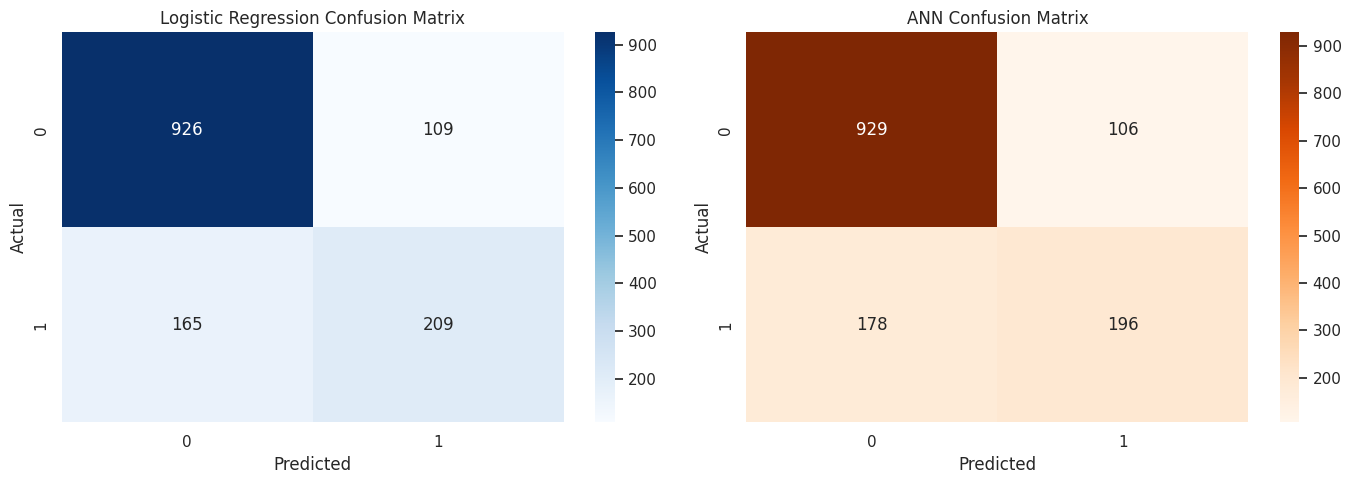

In [308]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Plot Confusion Matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Confusion Matrix
lr_cm = confusion_matrix(y_test, lr_preds)
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ANN Confusion Matrix
ann_cm = confusion_matrix(y_test, ann_preds)
sns.heatmap(ann_cm, annot=True, fmt='d', cmap='Oranges', ax=axes[1])
axes[1].set_title('ANN Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

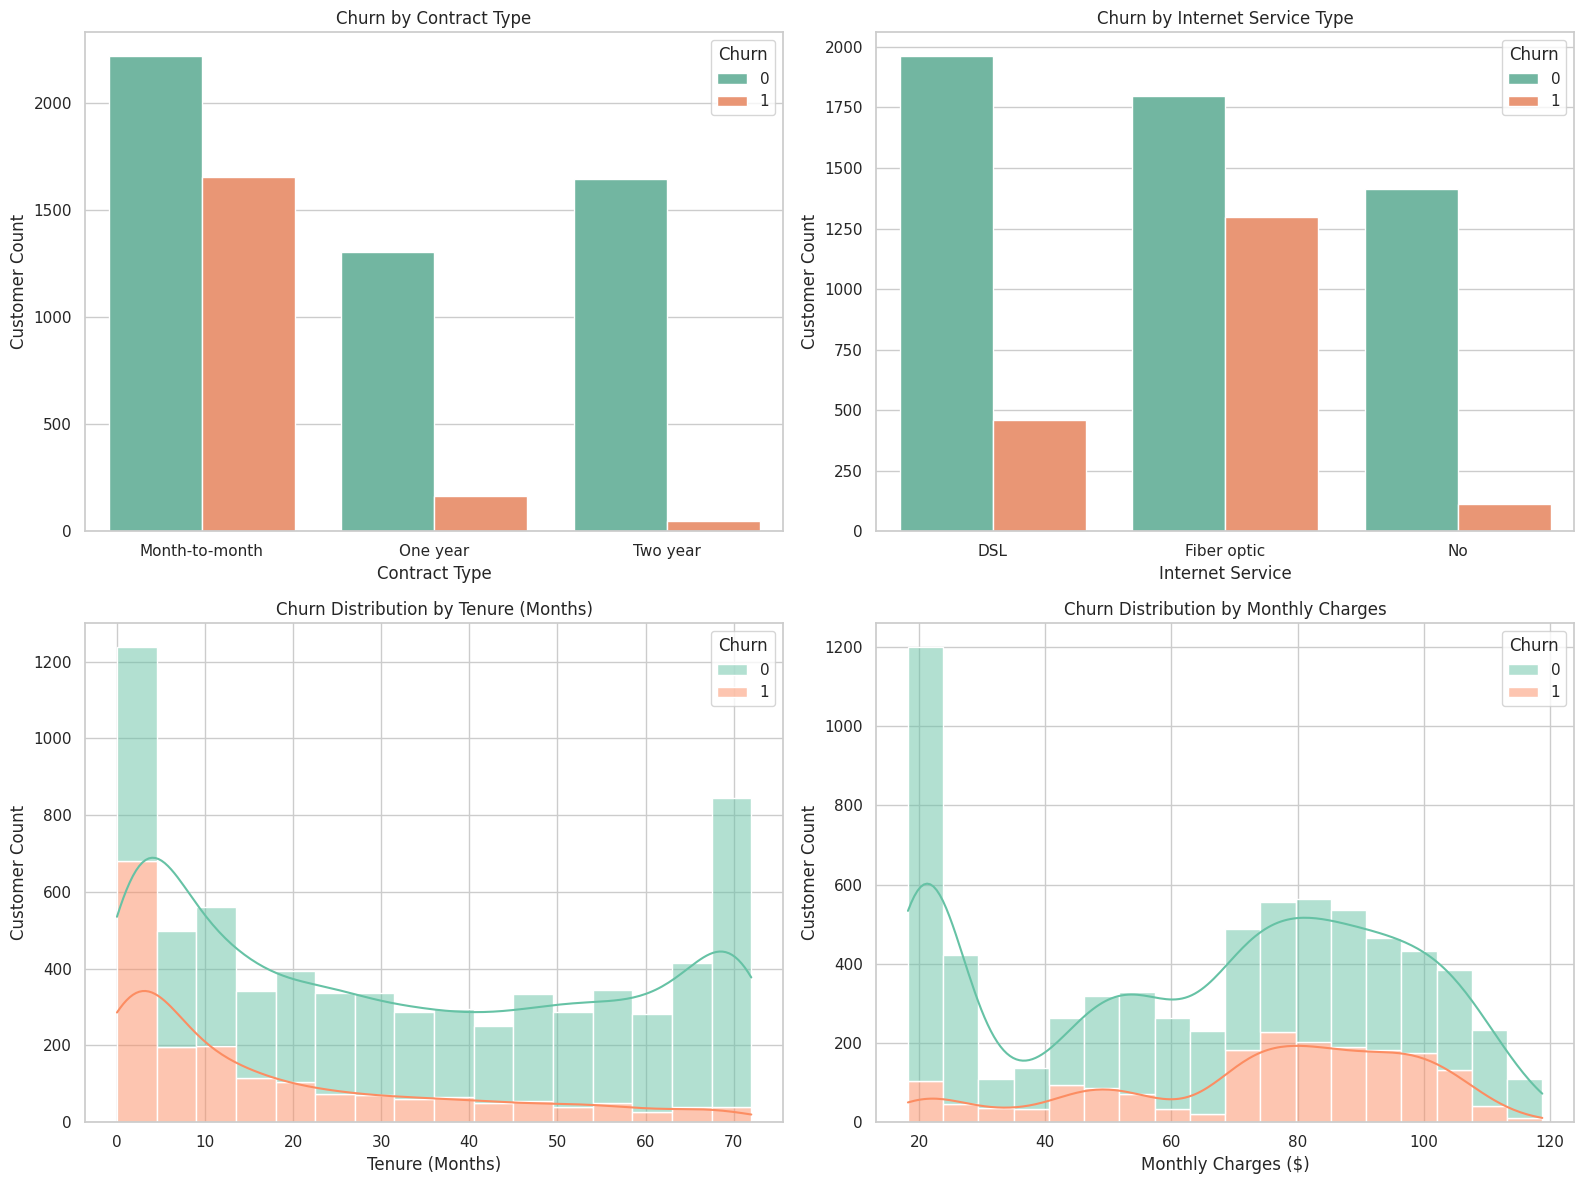

In [309]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Churn by Contract Type
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Churn by Contract Type')
axes[0, 0].set_xlabel('Contract Type')
axes[0, 0].set_ylabel('Customer Count')

# 2. Churn by Internet Service
sns.countplot(data=df, x='InternetService', hue='Churn', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Churn by Internet Service Type')
axes[0, 1].set_xlabel('Internet Service')
axes[0, 1].set_ylabel('Customer Count')

# 3. Churn by Tenure
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', kde=True, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Churn Distribution by Tenure (Months)')
axes[1, 0].set_xlabel('Tenure (Months)')
axes[1, 0].set_ylabel('Customer Count')

# 4. Churn by Monthly Charges
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', multiple='stack', kde=True, ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Churn Distribution by Monthly Charges')
axes[1, 1].set_xlabel('Monthly Charges ($)')
axes[1, 1].set_ylabel('Customer Count')

plt.tight_layout()
plt.show()

Part B — Exploratory Data Analysis (EDA)

Churn
0    5174
1    1869
Name: count, dtype: int64


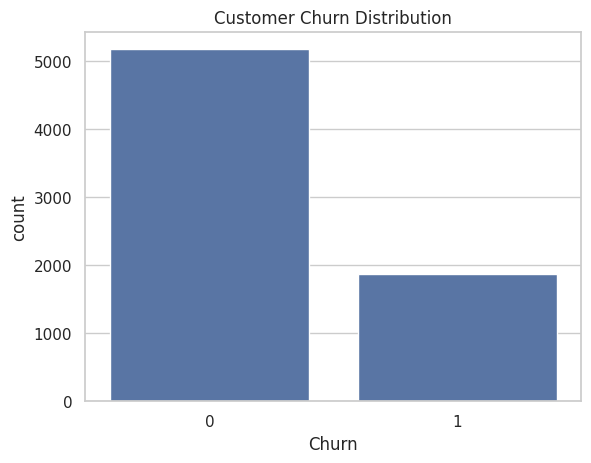

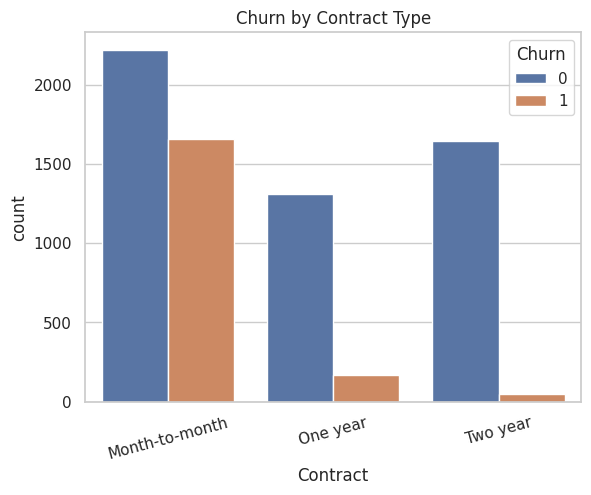

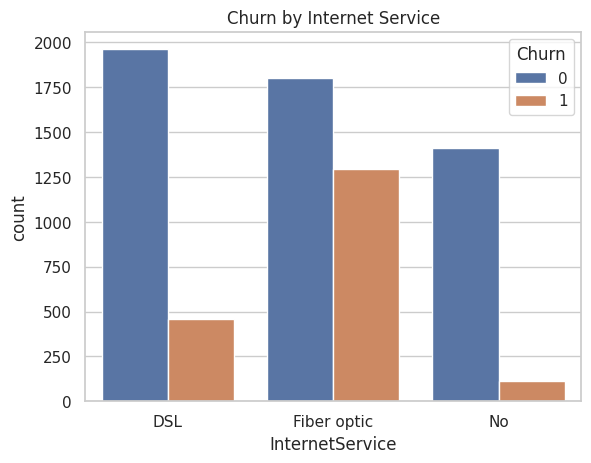

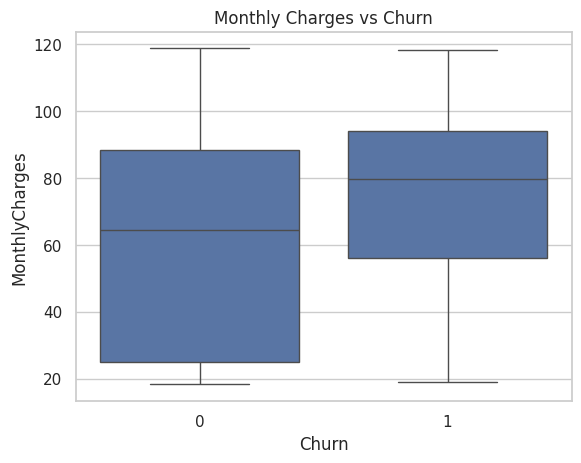

In [310]:
# Check the number of customers who left or stayed
print(df["Churn"].value_counts())

# Plot churn distribution
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

# Churn by contract type
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

# Churn by internet service
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Churn by Internet Service")
plt.show()

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Compare monthly charges
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

Questions to answer from your EDA:
Do customers on month-to-month contracts churn more?
Are customers with shorter tenure more likely to leave?
Does monthly spending appear related to churn?
Which customer groups might benefit from retention offers?
Use your actual charts to support your answers rather than assuming the results.

Part C — Prepare the data and train Logistic Regression

Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7559 - loss: 0.4972 - val_accuracy: 0.7862 - val_loss: 0.4533
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7948 - loss: 0.4304 - val_accuracy: 0.7844 - val_loss: 0.4479
Epoch 3/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7961 - loss: 0.4288 - val_accuracy: 0.7826 - val_loss: 0.4422
Epoch 4/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7990 - loss: 0.4242 - val_accuracy: 0.7853 - val_loss: 0.4397
Epoch 5/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8019 - loss: 0.4187 - val_accuracy: 0.7870 - val_loss: 0.4394
Epoch 6/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8061 - loss: 0.4158 - val_accuracy: 0.7897 - val_loss: 0.4373
Epoch 7/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8030 - loss: 0.4156 - val_accuracy: 0.7897 - val_loss: 0.4368
Epoch 8/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8050 - loss: 0.4094 - val_accuracy: 0.

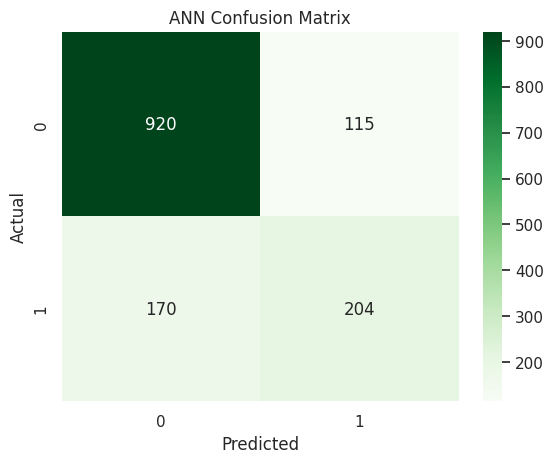

In [311]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# TensorFlow neural networks use dense arrays
X_train_processed = X_train_processed.toarray() \
    if hasattr(X_train_processed, "toarray") \
    else X_train_processed

X_test_processed = X_test_processed.toarray() \
    if hasattr(X_test_processed, "toarray") \
    else X_test_processed

# Build ANN
ann_model = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train ANN
ann_model.fit(
    X_train_processed,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Predict churn probabilities and classify
ann_prob = ann_model.predict(
    X_test_processed, verbose=0
).ravel()

ann_pred = (ann_prob >= 0.5).astype(int)

print("ANN Results")
print("Accuracy:", accuracy_score(y_test, ann_pred))
print("Precision:", precision_score(y_test, ann_pred))
print("Recall:", recall_score(y_test, ann_pred))

print(classification_report(y_test, ann_pred))

sns.heatmap(
    confusion_matrix(y_test, ann_pred),
    annot=True,
    fmt="d",
    cmap="Greens"
)
plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Important: The two models are trained independently, and the ANN preprocessing is fitted only on the training data. This avoids data leakage from the test set.
5. Understanding the evaluation metrics
Metric Meaning
Accuracy Percentage of all predictions that are correct.
Precision Of customers predicted to leave, how many actually left?

Recall Of all customers who actually left, how many did the model identify?
Confusion Matrix Shows correct and incorrect predictions for both classes.
For churn prediction, Recall for class 1 is especially important because missing customers who are about to leave may cost the company revenue.

Final conclusion template:
“ This project developed two binary classification models to predict customer churn. The models were evaluated using accuracy, precision, recall and confusion matrices. The results show which model is more suitable for identifying customers at risk of leaving, helping the telecom company plan customer retention strategies.”